# RQ1: Prediction Accuracy
**Research Question 1:** *How accurately does the IFS-based Recommender System predict missing stakeholder ratings?*

To answer this, we first evaluate the prediction quality across **all three RALIC datasets** (Objectives, Requirements, and Specific Requirements) using 10-fold cross-validation. The known ratings are randomly divided into 10 equal folds. In each run, 1 fold is removed (used as the test set) and predicted from the remaining 9 folds (training set).

We evaluate the Mean Absolute Error (MAE) against different fuzzification functions, hesitation degrees ($\pi$), nearest neighbors ($k$), and two distinct recommendation strategies:
* **Global:** Predicts based on overall stakeholder similarities.
* **Local:** Predicts based only on neighbors who have actively rated the target requirement.

Furthermore, to assess generalizability and isolate the empirical contribution of Intuitionistic Fuzzy Sets (IFS) and the H-max distance measure, we benchmark the proposed Local and Global IFS models against **five additional comparative baselines** (Crisp Euclidean CF, Crisp Cosine CF, SVD Matrix Factorization, User Mean, and Item Mean) across **four empirical datasets** (RALIC, Pharmacy Information System, IES Multi-Criteria, and MS Word Multi-Criteria), and compute **Partial Eta-Squared ($\eta_p^2$)** effect sizes in the multi-way ANOVA.

In [1]:
# Import core libraries for data manipulation, cross-validation, and performance evaluation
import os
import time
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error

# Import custom framework modules for data loading, fuzzification, similarity computation, prediction, and baselines
from src.data_loader import load_ralic, load_pharmacy, load_ies_multicriteria, load_msword_multicriteria
from src.fuzzification import convert_to_ifv_matrix, defuzzify_to_numeric
from src.similarity import get_similarity_matrices
from src.recommender import predict_missing_values
from src.baselines import predict_item_mean, predict_user_mean, predict_crisp_cf, predict_svd

# Configure global settings for output clarity and visualization styling
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

BASE_DATA_PATH = '../data/'
RESULTS_PATH = '../results/'
os.makedirs(RESULTS_PATH, exist_ok=True)

### 1. K-Fold Cross-Validation & Multi-Dataset Grid Search
We loop through RALIC datasets 1, 2, and 3. For each dataset, we extract all valid coordinates, run the 10-Fold CV, and test every combination of our framework parameters.

*(Note: Depending on the hardware, processing 3 datasets × 2 strategies × 3 fuzzification methods × 8 hesitation values × 75 neighbor limits × 10 folds = 108,000 matrix calculations may take a very long time to complete. The full grind results are already saved in the /results folder. To test and verify Specific Combination Parameters, change the appropriate parameters and run the following code.)*

In [2]:
# Full Grid Search Parameters - Uncomment as required to run the full grid search
# datasets = [1, 2, 3]  # 1: Objectives, 2: Requirements, 3: Specific Reqs
# strategies = ['global', 'local']
# fuzzification_methods = ['linear', 'r-trapezoidal', 'sigmoidal']
# hesitation_degrees = np.arange(0.0, 0.45, 0.05)
# k_neighbors_list = np.arange(1, 76)

# Specific Combination Parameters to run specific combinations - Comment as required to run the full grid search
datasets = [2]  # 1: Objectives, 2: Requirements, 3: Specific Reqs
strategies = ['global'] # 'global', 'local'
fuzzification_methods = ['linear'] # 'linear', 'r-trapezoidal', 'sigmoidal'
hesitation_degrees = [0.3] # 0.0 to 0.4 in steps of 0.05
k_neighbors_list = [29] # 1 to 75

results = []
total_start_time = time.time()

print("Starting K-Fold Cross-Validation Grid Search...")
print("=" * 80)

for data_id in datasets:
    print(f"\n>>> Loading RALIC Dataset {data_id}...")
    df_ralic, _, _, _ = load_ralic(data_id=data_id, base_path='../data/')
    valid_coords = np.argwhere(~df_ralic.isna().values)
    # Initialize k-fold split to validate predictive performance
    kf = KFold(n_splits=10, shuffle=True, random_state=100)
    
    for strategy in strategies:
        for method in fuzzification_methods:
            for pi in hesitation_degrees:
                for k_nn in k_neighbors_list:
                    fold_maes = []

                    for train_idx, test_idx in kf.split(valid_coords):
                        test_coords = valid_coords[test_idx]
                        
                        # Mask the test coordinates to simulate unrated requirements
                        df_train = df_ralic.copy()
                        for r, c in test_coords:
                            df_train.iat[r, c] = np.nan
                        
                        # Transform continuous numeric ratings into Intuitionistic Fuzzy Values (IFVs)
                        df_train_ifv = convert_to_ifv_matrix(
                            df_train, method=method, pi=pi, 
                            scale_min=-1.0, scale_max=5.0, trap_limit_min=0.0, trap_limit_max=4.0
                        )
                        
                        # Calculate pairwise stakeholder similarities using the H-max distance measure
                        _, sim_matrix = get_similarity_matrices(df_train_ifv)
                        
                        # Execute collaborative filtering to predict missing evaluations
                        df_pred_ifv = predict_missing_values(df_train_ifv, sim_matrix, k=k_nn, strategy=strategy)
                        
                        # Extract and defuzzify predicted values for error calculation
                        y_true = []
                        y_pred = []
                        
                        for r, c in test_coords:
                            true_val = df_ralic.iat[r, c]
                            pred_ifv = df_pred_ifv.iat[r, c]
                            
                            if isinstance(pred_ifv, tuple) and not np.isnan(pred_ifv[0]):
                                pred_val = defuzzify_to_numeric(pred_ifv, min_scale=-1.0, max_scale=5.0)
                            else:
                                # Apply default penalty constraint for completely disconnected nodes
                                pred_val = -1.0
                            
                            y_true.append(true_val)
                            y_pred.append(pred_val)
                        
                        if y_true:
                            fold_maes.append(mean_absolute_error(y_true, y_pred))
                    
                    # Aggregate Mean Absolute Error across all evaluation folds
                    avg_mae = np.mean(fold_maes)
                    results.append({
                        'Dataset': f'RALIC {data_id}', 
                        'Strategy': strategy,
                        'Fuzzification': method, 
                        'Uncertainty (pi)': pi, 
                        'Neighbors (k)': k_nn, 
                        'MAE': avg_mae
                    })
                    
                    print(f"Strategy: {strategy:<6} | Method: {method:<10} | pi: {pi:.2f} | k: {k_nn:<2} --> MAE: {avg_mae:.4f}")

print("=" * 80)
print(f"Grid Search Complete in {time.time() - total_start_time:.2f} seconds.")
df_results = pd.DataFrame(results)
display(df_results)

Starting K-Fold Cross-Validation Grid Search...

>>> Loading RALIC Dataset 2...
Strategy: global | Method: linear     | pi: 0.30 | k: 29 --> MAE: 0.8694
Grid Search Complete in 27.99 seconds.


,Dataset,Strategy,Fuzzification,Uncertainty (pi),Neighbors (k),MAE
0,RALIC 2,global,linear,0.3,29,0.869446


### 2. Exporting Results & Visualization
We save the output of the grid search into three distinct CSV files for downstream reporting, and we visualize the prediction accuracy using a multi-panel Seaborn grid.

*(Note: The full grid results are already saved as csv files in the /results folder and loaded for further analysis.)*

In [3]:
# Export the Full Grid Search Results
# df_results.to_csv('../results/rq1_ralic_mae_results.csv', index=False)

import pandas as pd
import matplotlib.pyplot as plt
results_path = '../results/rq1_ralic_mae_results.csv'

print(f"Loading full experimental results from '{results_path}'...\n")
df_results = pd.read_csv(results_path)

# Extract the best MAE for each Dataset, Strategy and Fuzzification
best_per_pi = df_results.loc[df_results.groupby(['Dataset', 'Strategy', 'Fuzzification'])['MAE'].idxmin()]
print("--- Best MAE for each Dataset, Strategy and Fuzzification ---")
display(best_per_pi[['Dataset', 'Strategy', 'Fuzzification', 'Uncertainty (pi)', 'Neighbors (k)', 'MAE']].style.format({'MAE': '{:.3f}'}).hide(axis="index"))

# Extract Best Overall MAE per Dataset and Strategy
best_overall = df_results.loc[df_results.groupby(['Dataset', 'Strategy'])['MAE'].idxmin()]
print("--- Absolute Best MAE per Dataset and Strategy ---")
display(best_overall[['Dataset', 'Strategy', 'Fuzzification', 'Uncertainty (pi)', 'Neighbors (k)', 'MAE']].style.format({'MAE': '{:.3f}'}).hide(axis="index"))

Loading full experimental results from '../results/rq1_ralic_mae_results.csv'...

--- Best MAE for each Dataset, Strategy and Fuzzification ---


Dataset,Strategy,Fuzzification,Uncertainty (pi),Neighbors (k),MAE
RALIC 1,global,linear,0.400000,44,0.789
RALIC 1,global,r-trapezoidal,0.400000,45,0.779
RALIC 1,global,sigmoidal,0.000000,44,0.792
RALIC 1,local,linear,0.250000,14,0.780
RALIC 1,local,r-trapezoidal,0.400000,14,0.757
RALIC 1,local,sigmoidal,0.000000,12,0.790
RALIC 2,global,linear,0.300000,29,0.869
RALIC 2,global,r-trapezoidal,0.400000,25,0.876
RALIC 2,global,sigmoidal,0.000000,40,0.996
RALIC 2,local,linear,0.150000,2,0.739


--- Absolute Best MAE per Dataset and Strategy ---


Dataset,Strategy,Fuzzification,Uncertainty (pi),Neighbors (k),MAE
RALIC 1,global,r-trapezoidal,0.400000,45,0.779
RALIC 1,local,r-trapezoidal,0.400000,14,0.757
RALIC 2,global,linear,0.300000,29,0.869
RALIC 2,local,linear,0.150000,2,0.739
RALIC 3,global,r-trapezoidal,0.400000,16,0.768
RALIC 3,local,linear,0.050000,2,0.607


### 3. Multi-Dataset & Comparative Baselines Evaluation (10-Fold CV)
To evaluate the effectiveness and generalizability of the proposed IFS-based Recommender System beyond the StakeRare benchmark, we compare the proposed Local and Global IFS strategies against five additional baselines:
1. **Crisp Euclidean CF:** Standard $k$-NN collaborative filtering using Euclidean similarity on crisp ratings.
2. **Crisp Cosine CF:** Standard $k$-NN collaborative filtering using Cosine similarity on crisp ratings.
3. **SVD Matrix Factorization:** Iterative low-rank Singular Value Decomposition centered on user/item biases.
4. **User Mean Heuristic:** Predicts missing ratings using the target stakeholder's mean observed rating.
5. **Item Mean Heuristic:** Predicts missing ratings using the target requirement's mean observed rating.

For the three **RALIC** hierarchy levels, the optimal Local and Global parameters (`Fuzzification`, `Uncertainty (pi)`, and `Neighbors (k)`) are dynamically extracted from the `best_overall` grid-search table computed in Section 2. The 10-fold cross-validation suite is also executed across the **Pharmacy Information System** dataset ($42 \times 101$), the **IES Multi-Criteria** dataset ($5 \times 192 \times 3$), and the **MS Word Multi-Criteria** dataset ($4 \times 50 \times 2$).

In [4]:
def evaluate_rq1_dataset(df_data, dataset_name, scale_min, scale_max, trap_b, trap_c,
                         local_params, global_params, stakerare_val=np.nan):
    """
    Runs 10-fold CV across the proposed IFS models (using distinct optimal parameters
    for Local and Global strategies) and all comparative baselines.
    """
    mth_loc, pi_loc, k_loc = local_params
    mth_glob, pi_glob, k_glob = global_params

    # Initialize k-fold split to validate predictive performance
    valid_coords = np.argwhere(~df_data.isna().values)
    kf = KFold(n_splits=10, shuffle=True, random_state=100)

    # Dictionary to aggregate Mean Absolute Error for each strategy
    maes = {
        'Proposed IFS (Local)': [],
        'Proposed IFS (Global)': [],
        'Crisp Euclidean CF': [],
        'Crisp Cosine CF': [],
        'SVD Matrix Factorization': [],
        'User Mean': [],
        'Item Mean': []
    }

    for _, test_idx in kf.split(valid_coords):
        test_coords = valid_coords[test_idx]

        # Mask the test coordinates to simulate unrated requirements
        df_train = df_data.copy()
        for r, c in test_coords:
            df_train.iat[r, c] = np.nan

        # Extract true target values
        y_true = [df_data.iat[r, c] for r, c in test_coords]

        # 1. Proposed IFS (Local)
        df_train_ifv_loc = convert_to_ifv_matrix(
            df_train, method=mth_loc, pi=pi_loc,
            scale_min=scale_min, scale_max=scale_max,
            trap_limit_min=trap_b, trap_limit_max=trap_c
        )
        _, sim_matrix_loc = get_similarity_matrices(df_train_ifv_loc)
        df_pred_loc = predict_missing_values(df_train_ifv_loc, sim_matrix_loc, k=k_loc, strategy='local')
        y_pred_loc = []
        for r, c in test_coords:
            val = defuzzify_to_numeric(df_pred_loc.iat[r, c], min_scale=scale_min, max_scale=scale_max)
            y_pred_loc.append(scale_min if np.isnan(val) else val)
        maes['Proposed IFS (Local)'].append(mean_absolute_error(y_true, y_pred_loc))

        # 2. Proposed IFS (Global) - reuse IFV & similarity matrix if method and pi match Local
        if (mth_glob == mth_loc) and np.isclose(pi_glob, pi_loc):
            df_train_ifv_glob, sim_matrix_glob = df_train_ifv_loc, sim_matrix_loc
        else:
            df_train_ifv_glob = convert_to_ifv_matrix(
                df_train, method=mth_glob, pi=pi_glob,
                scale_min=scale_min, scale_max=scale_max,
                trap_limit_min=trap_b, trap_limit_max=trap_c
            )
            _, sim_matrix_glob = get_similarity_matrices(df_train_ifv_glob)

        df_pred_glob = predict_missing_values(df_train_ifv_glob, sim_matrix_glob, k=k_glob, strategy='global')
        y_pred_glob = []
        for r, c in test_coords:
            val = defuzzify_to_numeric(df_pred_glob.iat[r, c], min_scale=scale_min, max_scale=scale_max)
            y_pred_glob.append(scale_min if np.isnan(val) else val)
        maes['Proposed IFS (Global)'].append(mean_absolute_error(y_true, y_pred_glob))

        # 3 & 4. Crisp Collaborative Filtering (Euclidean & Cosine)
        df_euc = predict_crisp_cf(df_train, k=k_loc, metric='euclidean',
                                  strategy='local', scale_min=scale_min, scale_max=scale_max)
        maes['Crisp Euclidean CF'].append(
            mean_absolute_error(y_true, [df_euc.iat[r, c] for r, c in test_coords])
        )

        df_cos = predict_crisp_cf(df_train, k=k_loc, metric='cosine',
                                  strategy='local', scale_min=scale_min, scale_max=scale_max)
        maes['Crisp Cosine CF'].append(
            mean_absolute_error(y_true, [df_cos.iat[r, c] for r, c in test_coords])
        )

        # 5. SVD Matrix Factorization
        df_svd = predict_svd(df_train, n_factors=3, scale_min=scale_min, scale_max=scale_max)
        maes['SVD Matrix Factorization'].append(
            mean_absolute_error(y_true, [df_svd.iat[r, c] for r, c in test_coords])
        )

        # 6 & 7. Simple Heuristics (User Mean & Item Mean)
        df_um = predict_user_mean(df_train, default_val=(scale_min + scale_max) / 2.0)
        maes['User Mean'].append(
            mean_absolute_error(y_true, [df_um.iat[r, c] for r, c in test_coords])
        )

        df_im = predict_item_mean(df_train, default_val=(scale_min + scale_max) / 2.0)
        maes['Item Mean'].append(
            mean_absolute_error(y_true, [df_im.iat[r, c] for r, c in test_coords])
        )

    # Aggregate findings to formulate summary row
    summary = {'Dataset': dataset_name}
    for model_name, fold_list in maes.items():
        summary[model_name] = round(float(np.mean(fold_list)), 4)
    summary['StakeRare [10]'] = stakerare_val
    return summary


print("Running RQ1 10-Fold CV Baseline Suite Across All Datasets...")
rq1_rows = []

# Literature StakeRare MAE values for the three RALIC hierarchy levels
stakerare_baselines = {
    'RALIC 1': 0.8890,
    'RALIC 2': 1.0070,
    'RALIC 3': 0.9640
}

ralic_hierarchy_map = {
    1: ('RALIC 1', 'RALIC 1 (Objectives)'),
    2: ('RALIC 2', 'RALIC 2 (Requirements)'),
    3: ('RALIC 3', 'RALIC 3 (Specific Reqs)')
}

# Dynamically extract optimal Local and Global parameters from 'best_overall' (computed in Section 2)
for d_id, (ds_key, ds_name) in ralic_hierarchy_map.items():
    row_loc = best_overall[(best_overall['Dataset'] == ds_key) & (best_overall['Strategy'] == 'local')].iloc[0]
    row_glob = best_overall[(best_overall['Dataset'] == ds_key) & (best_overall['Strategy'] == 'global')].iloc[0]

    loc_p = (row_loc['Fuzzification'], float(row_loc['Uncertainty (pi)']), int(row_loc['Neighbors (k)']))
    glob_p = (row_glob['Fuzzification'], float(row_glob['Uncertainty (pi)']), int(row_glob['Neighbors (k)']))
    sr_val = stakerare_baselines[ds_key]

    df_r, _, _, _ = load_ralic(data_id=d_id, base_path=BASE_DATA_PATH)
    rq1_rows.append(evaluate_rq1_dataset(df_r, ds_name, -1.0, 5.0, 0.0, 4.0, loc_p, glob_p, stakerare_val=sr_val))

# Process auxiliary single-criterion and multi-criteria datasets
df_pharm, _, _, _, _ = load_pharmacy(BASE_DATA_PATH)
rq1_rows.append(evaluate_rq1_dataset(
    df_pharm, 'Pharmacy (42x101)', 1.0, 5.0, 1.5, 4.5,
    local_params=('r-trapezoidal', 0.20, 5), global_params=('r-trapezoidal', 0.20, 15)
))

df_ies, _, _, _, _ = load_ies_multicriteria(BASE_DATA_PATH)
rq1_rows.append(evaluate_rq1_dataset(
    df_ies, 'IES Multi-Criteria (5x192x3)', 1.0, 5.0, 1.5, 4.5,
    local_params=('linear', 0.15, 2), global_params=('linear', 0.15, 3)
))

df_msw, _, _, _, _ = load_msword_multicriteria(BASE_DATA_PATH)
rq1_rows.append(evaluate_rq1_dataset(
    df_msw, 'MS Word Multi-Criteria (4x50x2)', 1.0, 9.0, 2.0, 8.0,
    local_params=('linear', 0.15, 2), global_params=('linear', 0.15, 3)
))

df_rq1_base = pd.DataFrame(rq1_rows)

# Compute RALIC Mean (Levels 1-3) and All-Dataset Mean rows
ralic_mean_row = df_rq1_base.iloc[:3].mean(numeric_only=True).round(4).to_dict()
ralic_mean_row['Dataset'] = 'RALIC Mean (Levels 1–3)'

all_mean_row = df_rq1_base.iloc[:6].mean(numeric_only=True).round(4).to_dict()
all_mean_row['Dataset'] = 'All-Dataset Mean'
all_mean_row['StakeRare [10]'] = np.nan

# Combine into final summary DataFrame and export to CSV
df_rq1_summary = pd.concat([df_rq1_base, pd.DataFrame([ralic_mean_row, all_mean_row])], ignore_index=True)
df_rq1_summary.to_csv(os.path.join(RESULTS_PATH, 'rq1_all_datasets_mae_baselines.csv'), index=False)

print("\n--- 10-Fold CV MAE Comparison Across All Datasets & Baselines ---")
display(df_rq1_summary.style.format(
    {col: '{:.3f}' for col in df_rq1_summary.columns if col != 'Dataset'},
    na_rep='—'
).hide(axis="index"))

Running RQ1 10-Fold CV Baseline Suite Across All Datasets...

--- 10-Fold CV MAE Comparison Across All Datasets & Baselines ---


Dataset,Proposed IFS (Local),Proposed IFS (Global),Crisp Euclidean CF,Crisp Cosine CF,SVD Matrix Factorization,User Mean,Item Mean,StakeRare [10]
RALIC 1 (Objectives),0.757,0.779,0.807,0.857,0.922,0.885,0.927,0.889
RALIC 2 (Requirements),0.739,0.869,0.774,0.976,0.750,0.890,1.088,1.007
RALIC 3 (Specific Reqs),0.607,0.768,0.632,0.854,0.580,0.877,1.069,0.964
Pharmacy (42x101),0.727,0.761,0.743,0.881,0.674,0.737,0.892,—
IES Multi-Criteria (5x192x3),0.904,0.893,0.895,0.909,0.920,0.885,0.896,—
MS Word Multi-Criteria (4x50x2),2.078,2.040,2.179,2.171,2.248,2.361,2.038,—
RALIC Mean (Levels 1–3),0.701,0.805,0.738,0.895,0.751,0.884,1.028,0.953
All-Dataset Mean,0.969,1.018,1.005,1.108,1.016,1.106,1.152,—


### 3.1 Visualization: Proposed Framework vs. Comparative Baselines (RALIC)
We visualize the 10-fold cross-validation MAE of the optimal Global and Local configurations of our proposed IFS-based Recommender System alongside the comparative baselines (**Crisp Euclidean CF**, **SVD Matrix Factorization**, **User Mean**, and **StakeRare**) across all three RALIC hierarchy levels and their overall average.

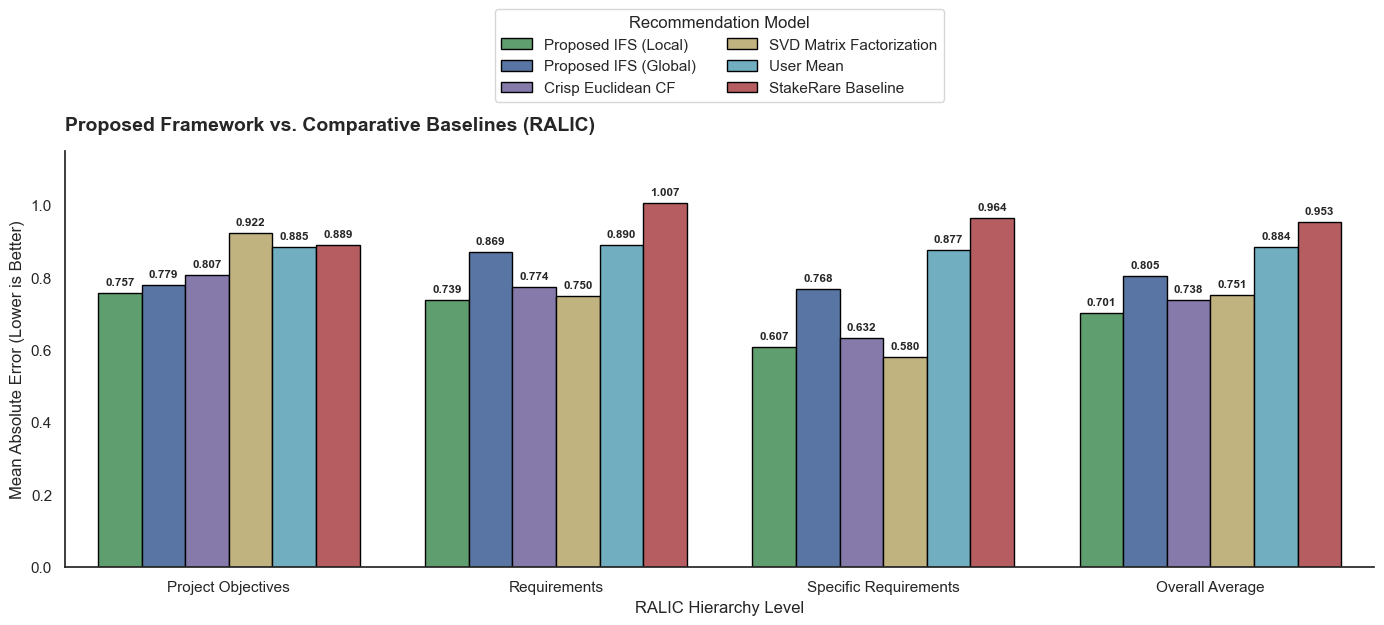

In [5]:
# Map RALIC dataset labels to clean hierarchy titles for plotting
dataset_titles = {
    'RALIC 1 (Objectives)': 'Project Objectives',
    'RALIC 2 (Requirements)': 'Requirements',
    'RALIC 3 (Specific Reqs)': 'Specific Requirements',
    'RALIC Mean (Levels 1–3)': 'Overall Average'
}

# Filter the summary table to the RALIC hierarchy levels and their Overall Average
df_ralic_plot = df_rq1_summary[df_rq1_summary['Dataset'].isin(dataset_titles.keys())].copy()
df_ralic_plot['Dataset_Clean'] = df_ralic_plot['Dataset'].map(dataset_titles)

# Select the primary models to display for a clean, readable grouped bar chart
models_to_plot = [
    'Proposed IFS (Local)',
    'Proposed IFS (Global)',
    'Crisp Euclidean CF',
    'SVD Matrix Factorization',
    'User Mean',
    'StakeRare [10]'
]

model_display_names = {
    'Proposed IFS (Local)': 'Proposed IFS (Local)',
    'Proposed IFS (Global)': 'Proposed IFS (Global)',
    'Crisp Euclidean CF': 'Crisp Euclidean CF',
    'SVD Matrix Factorization': 'SVD Matrix Factorization',
    'User Mean': 'User Mean',
    'StakeRare [10]': 'StakeRare Baseline'
}

# Restructure data for a grouped bar chart
plot_data = []
for _, row in df_ralic_plot.iterrows():
    for m in models_to_plot:
        plot_data.append({
            'Dataset': row['Dataset_Clean'],
            'Recommendation Model': model_display_names[m],
            'MAE': row[m]
        })

plot_df = pd.DataFrame(plot_data)

# Set visualization style (white background, no grids)
sns.set_theme(style="white")
plt.figure(figsize=(14, 6.5))

# Define custom colors to match the manuscript aesthetic
custom_palette = {
    'Proposed IFS (Local)': '#55A868',       # Green (Best Overall)
    'Proposed IFS (Global)': '#4C72B0',      # Blue
    'Crisp Euclidean CF': '#8172B2',         # Purple
    'SVD Matrix Factorization': '#CCB974',   # Gold
    'User Mean': '#64B5CD',                  # Cyan
    'StakeRare Baseline': '#C44E52'          # Red
}

# Generate grouped bar plot (errorbar=None removes vertical lines on bars)
ax = sns.barplot(
    data=plot_df,
    x='Dataset',
    y='MAE',
    hue='Recommendation Model',
    palette=custom_palette,
    edgecolor='black',
    linewidth=1.0,
    errorbar=None
)

# Annotate bars with precise MAE values
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.3f}',
                    xy=(p.get_x() + p.get_width() / 2, height),
                    xytext=(0, 4),  # 4 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=8.5, fontweight='bold')

# Set title and axes labels
plt.title('Proposed Framework vs. Comparative Baselines (RALIC)',
          fontsize=14, weight='bold', loc='left', pad=15)
plt.ylabel('Mean Absolute Error (Lower is Better)', fontsize=12)
plt.xlabel('RALIC Hierarchy Level', fontsize=12)
plt.ylim(0, 1.15)

# Move legend outside the plot
plt.legend(title='Recommendation Model', bbox_to_anchor=(0.5, 1.1), loc='lower center', ncol=2, frameon=True)

# Remove top and right borders for a cleaner look
sns.despine()

plt.tight_layout()
plt.savefig('../results/rq1_all_datasets_mae_baselines.png', dpi=600, bbox_inches='tight')
plt.show()

### 4. Statistical Analysis (ANOVA with Partial Eta-Squared $\eta_p^2$ & Tukey HSD)
To evaluate the statistical and practical significance of the proposed approach, we apply a multi-way Analysis of Variance (ANOVA) to the MAE metric across $k$-nn, fuzzification function, hesitation degree ($\pi$), and recommendation strategy, and compute **Partial Eta-Squared ($\eta_p^2 = SS_{\text{effect}} / (SS_{\text{effect}} + SS_{\text{error}})$)** effect sizes.

Following the ANOVA, we perform a Multiple Pairwise Comparison (Tukey HSD) to explicitly identify which fuzzification functions yield statistically different performance.

In [6]:
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import warnings
import pandas as pd

# Suppress statsmodels warnings for cleaner output
warnings.filterwarnings('ignore', module='statsmodels')

# Load the complete experimental dataset for variance analysis
results_path = '../results/rq1_ralic_mae_results.csv'
df_results = pd.read_csv(results_path)
df_anova = df_results.copy()

# Sanitize structural column names to comply with statsmodels formula conventions
df_anova = df_anova.rename(columns={
    'Neighbors (k)': 'knn',
    'Uncertainty (pi)': 'hesitation',
    'Fuzzification': 'fuzzification',
    'Strategy': 'strategy'
})

all_anova_tables = []

# Execute independent statistical models for each evaluation dataset
for dataset in df_anova['Dataset'].unique():
    print(f"\n{'='*80}")
    print(f"STATISTICAL ANALYSIS: {dataset}")
    print(f"{'='*80}")

    df_ds = df_anova[df_anova['Dataset'] == dataset]

    # Define the N-Way ANOVA formula
    # Model: MAE influenced by knn, fuzzification, hesitation, strategy, and their key interactions
    formula = (
        'MAE ~ C(knn) + C(fuzzification) + C(hesitation) + C(strategy) + '
        'C(knn):C(hesitation) + C(knn):C(fuzzification) + C(knn):C(strategy) + '
        'C(fuzzification):C(hesitation) + C(fuzzification):C(strategy) + '
        'C(hesitation):C(strategy)'
    )

    print("Fitting ANOVA model...")
    model = ols(formula, data=df_ds).fit()
    anova_results = sm.stats.anova_lm(model, typ=2)

    # Calculate Mean Square variances and Partial Eta-Squared effect sizes
    ss_err = anova_results.loc['Residual', 'sum_sq']
    anova_results['Mean Square'] = anova_results['sum_sq'] / anova_results['df']
    anova_results['Partial_Eta_Sq'] = anova_results['sum_sq'] / (anova_results['sum_sq'] + ss_err)
    anova_results.loc['Residual', 'Partial_Eta_Sq'] = np.nan

    # Store for CSV export
    res_export = anova_results.reset_index().rename(columns={'index': 'Source', 'Mean Square': 'Mean_Square'})
    res_export['Dataset'] = dataset
    all_anova_tables.append(res_export)

    anova_formatted = pd.DataFrame({
        'Source': anova_results.index,
        'Sum of Squares': anova_results['sum_sq'],
        'df': anova_results['df'],
        'Mean Square': anova_results['Mean Square'],
        'F': anova_results['F'],
        'Sig.': anova_results['PR(>F)'],
        'Partial Eta Sq': anova_results['Partial_Eta_Sq']
    }).reset_index(drop=True)

    # Standardize residual labeling
    anova_formatted['Source'] = anova_formatted['Source'].replace('Residual', 'Error')

    print(f"\nTable: Results of ANOVA for MAE (with Partial Eta-Squared) - {dataset}")
    display(anova_formatted.style.format({
        'Sum of Squares': '{:.3f}',
        'df': '{:.0f}',
        'Mean Square': '{:.3f}',
        'F': '{:.2f}',
        'Sig.': '{:.3f}',
        'Partial Eta Sq': '{:.3f}'
    }).hide(axis="index"))

    # TUKEY HSD (Pairwise Comparisons for Fuzzification)
    # Performs post-hoc analysis to find exactly which functions outperformed the others
    tukey = pairwise_tukeyhsd(endog=df_ds['MAE'], groups=df_ds['fuzzification'], alpha=0.01)
    tukey_df = pd.DataFrame(data=tukey._results_table.data[1:], columns=tukey._results_table.data[0])

    # Construct tabular representation of pairwise mean differences and confidence intervals
    tukey_formatted = pd.DataFrame({
        'Group 1': tukey_df['group1'],
        'Group 2': tukey_df['group2'],
        'Mean Difference': tukey_df['meandiff'],
        'Lower Bound': tukey_df['lower'],
        'Upper Bound': tukey_df['upper'],
        'p-value': tukey_df['p-adj']
    })

    # Format high-significance thresholds dynamically
    tukey_formatted['p-value'] = tukey_formatted['p-value'].apply(lambda x: '<.001' if x < 0.001 else f"{x:.3f}")

    print(f"\nTable: Multiple pairwise comparisons for fuzzification - {dataset}")
    display(tukey_formatted.style.format({
        'Mean Difference': '{:.3f}',
        'Lower Bound': '{:.3f}',
        'Upper Bound': '{:.3f}'
    }).hide(axis="index"))

# Export compiled ANOVA statistics with Partial Eta-Squared to CSV
df_anova_out = pd.concat(all_anova_tables, ignore_index=True)
anova_out_path = os.path.join(RESULTS_PATH, 'rq1_anova_with_effect_sizes.csv')
df_anova_out.to_csv(anova_out_path, index=False)
print(f"\nSaved compiled ANOVA table with Partial Eta-Squared to '{anova_out_path}'.")


STATISTICAL ANALYSIS: RALIC 1
Fitting ANOVA model...

Table: Results of ANOVA for MAE (with Partial Eta-Squared) - RALIC 1


Source,Sum of Squares,df,Mean Square,F,Sig.,Partial Eta Sq
C(knn),56.133,74,0.759,5667.08,0.000,0.993
C(fuzzification),6.335,2,3.168,23664.65,0.000,0.938
C(hesitation),2.985,8,0.373,2787.29,0.000,0.877
C(strategy),4.874,1,4.874,36414.86,0.000,0.921
C(knn):C(hesitation),0.121,592,0.000,1.53,0.000,0.224
C(knn):C(fuzzification),0.129,148,0.001,6.52,0.000,0.236
C(knn):C(strategy),38.613,74,0.522,3898.37,0.000,0.989
C(fuzzification):C(hesitation),6.398,16,0.400,2987.47,0.000,0.939
C(fuzzification):C(strategy),0.006,2,0.003,22.06,0.000,0.014
C(hesitation):C(strategy),0.006,8,0.001,5.81,0.000,0.015



Table: Multiple pairwise comparisons for fuzzification - RALIC 1


Group 1,Group 2,Mean Difference,Lower Bound,Upper Bound,p-value
linear,r-trapezoidal,-0.032,-0.050,-0.013,<.001
linear,sigmoidal,0.063,0.045,0.082,<.001
r-trapezoidal,sigmoidal,0.095,0.077,0.114,<.001



STATISTICAL ANALYSIS: RALIC 2
Fitting ANOVA model...

Table: Results of ANOVA for MAE (with Partial Eta-Squared) - RALIC 2


Source,Sum of Squares,df,Mean Square,F,Sig.,Partial Eta Sq
C(knn),26.492,74,0.358,1531.14,0.000,0.973
C(fuzzification),7.139,2,3.570,15266.78,0.000,0.907
C(hesitation),0.134,8,0.017,71.87,0.000,0.155
C(strategy),3.563,1,3.563,15238.21,0.000,0.830
C(knn):C(hesitation),0.341,592,0.001,2.47,0.000,0.319
C(knn):C(fuzzification),1.973,148,0.013,57.02,0.000,0.730
C(knn):C(strategy),30.981,74,0.419,1790.64,0.000,0.977
C(fuzzification):C(hesitation),1.988,16,0.124,531.54,0.000,0.731
C(fuzzification):C(strategy),0.048,2,0.024,101.99,0.000,0.061
C(hesitation):C(strategy),0.025,8,0.003,13.21,0.000,0.033


... (3 outputs left out)

Source,Sum of Squares,df,Mean Square,F,Sig.,Partial Eta Sq
C(knn),27.595,74,0.373,958.61,0.000,0.958
C(fuzzification),11.220,2,5.610,14421.64,0.000,0.902
C(hesitation),0.112,8,0.014,35.92,0.000,0.084
C(strategy),0.935,1,0.935,2403.87,0.000,0.435
C(knn):C(hesitation),0.338,592,0.001,1.47,0.000,0.217
C(knn):C(fuzzification),2.912,148,0.020,50.57,0.000,0.706
C(knn):C(strategy),19.407,74,0.262,674.16,0.000,0.941
C(fuzzification):C(hesitation),2.964,16,0.185,476.13,0.000,0.709
C(fuzzification):C(strategy),0.041,2,0.020,52.61,0.000,0.033
C(hesitation):C(strategy),0.017,8,0.002,5.59,0.000,0.014



Table: Multiple pairwise comparisons for fuzzification - RALIC 3


Group 1,Group 2,Mean Difference,Lower Bound,Upper Bound,p-value
linear,r-trapezoidal,0.045,0.032,0.058,<.001
linear,sigmoidal,0.127,0.114,0.140,<.001
r-trapezoidal,sigmoidal,0.082,0.069,0.095,<.001



Saved compiled ANOVA table with Partial Eta-Squared to '../results/rq1_anova_with_effect_sizes.csv'.
